# Week 2, core 2: Regularization — Ridge and Lasso

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cdds-uiuc/applied-ai-earth-sciences/blob/main/week02_regression_regularization/W02_core2_ridge_lasso.ipynb)

Polynomial degree is one flexibility dial. The dial used almost everywhere in modern machine learning is different: keep the flexible model, but **penalize large coefficients**. That is regularization. This notebook shows the two classic forms on linear regression, Ridge and Lasso, and the one preparation step they both demand.

## What you will learn

- How a penalty on the coefficients added to the loss trades a little bias for a lot less variance.
- The difference between Ridge (shrinks coefficients but never to exactly zero) and Lasso (sets some coefficients exactly to zero, selecting features).
- Why features must be standardized before regularization, and how the penalty strength is chosen on a validation set.


In [1]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## Many features, few that matter

Real Earth-science tables have many columns, often correlated, of which only a few drive the quantity we care about. We build a synthetic version: 100 samples of 50 features where only the first 5 affect the target, with the features mixed so that they are correlated with each other, as climate variables always are.


In [2]:
n_samples, n_features, n_informative = 100, 50, 5

Z = np.random.normal(size=(n_samples, n_features))                   # independent sources, (100, 50)
mixing = np.eye(n_features) + 0.6 * np.random.normal(size=(n_features, n_features)) / np.sqrt(n_features)
X = Z @ mixing                                                       # correlated features, (100, 50)

w_true = np.zeros(n_features)
w_true[:n_informative] = [3.0, -2.0, 1.5, 1.0, 0.8]                 # only five features matter
noise_level = 1.0
y = X @ w_true + np.random.normal(0, noise_level, n_samples)          # (100,)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=seed)
print(X_train.shape, X_test.shape)


(70, 50) (30, 50)


## Ordinary least squares struggles

With 70 training samples and 50 correlated features, plain linear regression (ordinary least squares, OLS) can fit the training data well, but its coefficients are unstable: correlated features can trade off against each other, and the estimates come out large and noisy.


OLS   train RMSE 0.535   test RMSE 1.946


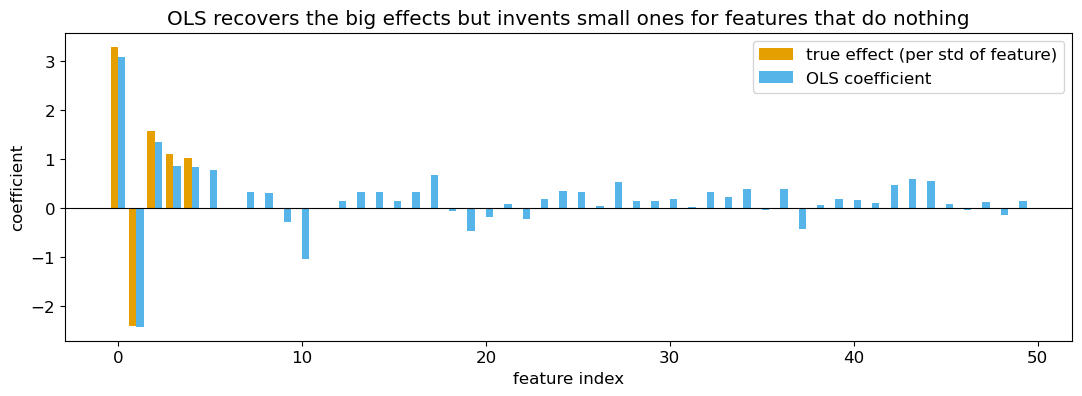

In [3]:
def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

scaler = StandardScaler().fit(X_train)                 # standardize: the penalty must treat every feature equally
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

ols = LinearRegression().fit(X_train_std, y_train)
print(f"OLS   train RMSE {rmse(y_train, ols.predict(X_train_std)):.3f}   test RMSE {rmse(y_test, ols.predict(X_test_std)):.3f}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(np.arange(n_features) - 0.2, w_true * scaler.scale_, width=0.4, label="true effect (per std of feature)")
ax.bar(np.arange(n_features) + 0.2, ols.coef_, width=0.4, label="OLS coefficient")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("feature index")
ax.set_ylabel("coefficient")
ax.set_title("OLS recovers the big effects but invents small ones for features that do nothing")
ax.legend()
plt.show()


The five informative features (indices 0–4) come out roughly right, but the forty-five features that have no effect receive non-zero coefficients, some sizeable, purely from noise. On new data those spurious coefficients add error.

## Ridge: penalize the squared coefficients

Ridge regression minimizes the training MSE **plus** a penalty proportional to the sum of squared coefficients:

$$\text{loss}_{\text{ridge}}(\mathbf{w}, b) = \text{MSE}(\mathbf{w}, b) + \alpha \sum_{j} w_j^2 .$$

The number $\alpha$ (`alpha` in scikit-learn) sets how expensive large coefficients are. With $\alpha = 0$ this is OLS; as $\alpha$ grows, every coefficient is pulled toward zero (**shrinkage**), the fit gets stiffer, variance falls and bias rises, exactly the dial of the previous notebook. Because the penalty compares coefficients across features, every feature must be on the same scale first: hence the `StandardScaler`.

(A footnote for the careful reader: scikit-learn's `Ridge` adds its `alpha` times the squared coefficients to the *sum* of squared errors rather than to the mean, and `Lasso` works with half the mean squared error, so the library's `alpha` is our $\alpha$ scaled by $n$ for Ridge and by one half for Lasso. Nothing below depends on this, except that a Ridge alpha and a Lasso alpha are not comparable on one axis, and a Ridge alpha chosen at one sample size is a slightly different penalty at another.)


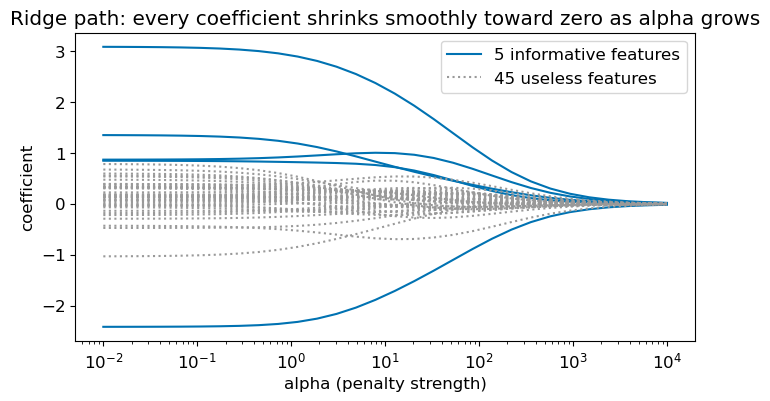

In [4]:
alphas = np.logspace(-2, 4, 30)                                     # 0.01 ... 10000, evenly spaced in log10

ridge_paths = np.zeros((len(alphas), n_features))                    # (n_alphas, n_features)
for i, alpha in enumerate(alphas):
    ridge = Ridge(alpha=alpha).fit(X_train_std, y_train)
    ridge_paths[i] = ridge.coef_

fig, ax = plt.subplots()
for j in range(n_features):
    style = "-" if j < n_informative else ":"
    ax.plot(alphas, ridge_paths[:, j], style, color="#0072B2" if j < n_informative else "#999999")
ax.plot([], [], "-", color="#0072B2", label="5 informative features")        # legend entries for the two line classes
ax.plot([], [], ":", color="#999999", label="45 useless features")
ax.legend()
ax.set_xscale("log")
ax.set_xlabel("alpha (penalty strength)")
ax.set_ylabel("coefficient")
ax.set_title("Ridge path: every coefficient shrinks smoothly toward zero as alpha grows")
plt.show()


Solid blue lines are the five informative features, dotted gray the forty-five useless ones. As alpha grows, all coefficients shrink smoothly toward zero; the useless ones get small quickly, the useful ones hold out longer, but none reaches exactly zero.

## Lasso: penalize the absolute coefficients

Lasso changes one thing: the penalty is the sum of **absolute** coefficients,

$$\text{loss}_{\text{lasso}}(\mathbf{w}, b) = \text{MSE}(\mathbf{w}, b) + \alpha \sum_{j} |w_j| .$$

That small change has a big consequence: as alpha grows, coefficients do not just shrink, they hit **exactly zero** and stay there. Lasso therefore *selects* features, and the surviving ones are the model's answer to "which inputs matter?".


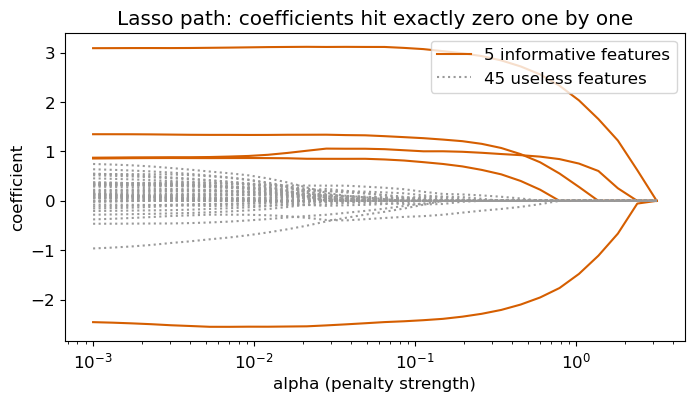

number of non-zero coefficients at each alpha: [49, 49, 50, 48, 48, 46, 46, 44, 44, 44, 42, 42, 38, 31, 28, 24, 21, 18, 13, 10, 8, 7, 7, 7, 4, 4, 3, 3, 2, 0]


In [5]:
alphas_lasso = np.logspace(-3, 0.5, 30)

lasso_paths = np.zeros((len(alphas_lasso), n_features))
for i, alpha in enumerate(alphas_lasso):
    lasso = Lasso(alpha=alpha, max_iter=20000).fit(X_train_std, y_train)     # max_iter raised: Lasso's solver needs more iterations than the default at small alpha
    lasso_paths[i] = lasso.coef_

fig, ax = plt.subplots()
for j in range(n_features):
    style = "-" if j < n_informative else ":"
    ax.plot(alphas_lasso, lasso_paths[:, j], style, color="#D55E00" if j < n_informative else "#999999")
ax.plot([], [], "-", color="#D55E00", label="5 informative features")
ax.plot([], [], ":", color="#999999", label="45 useless features")
ax.legend()
ax.set_xscale("log")
ax.set_xlabel("alpha (penalty strength)")
ax.set_ylabel("coefficient")
ax.set_title("Lasso path: coefficients hit exactly zero one by one")
plt.show()

n_nonzero = (lasso_paths != 0).sum(axis=1)
print("number of non-zero coefficients at each alpha:", n_nonzero.tolist())


The gray (useless) coefficients are driven to exactly zero at small alpha; the five orange (informative) ones survive longest, then disappear in order of effect size. At the right alpha, Lasso returns close to the five features that generated the data.

> **Exercise.** Predict what happens to the Lasso coefficients if `alpha` is made very large, say 10: how many non-zero coefficients remain, and what does the model then predict for every sample? Write it down, then fit `Lasso(alpha=10)` on `X_train_std, y_train` in the cell below and check `lasso.coef_` and `lasso.intercept_` (compare the intercept with `y_train.mean()`).


In [6]:
# Exercise 1: work here
np.random.seed(seed)


> **Check your understanding.** Two features are almost perfect copies of each other and both matter. Which method is more likely to keep both with similar coefficients, Ridge or Lasso, and which is more likely to keep one and drop the other?

## Choosing alpha on a validation set

Alpha is a flexibility dial, so it must be chosen on data the model did not see. But the test set is reserved for the final honest number, so we split the training set once more into a smaller training part and a **validation** part, choose alpha on the validation RMSE, and only then touch the test set. (`X_fit` is the part of the training set we fit on; the lab splits the same way but names the pieces `X_train` and `X_val` after setting `X_test` aside.) (Week 3 replaces this single split with cross-validation, which uses the data more efficiently.)


(49, 50) (21, 50)
ridge: best alpha on validation = 7.88
lasso: best alpha on validation = 0.196


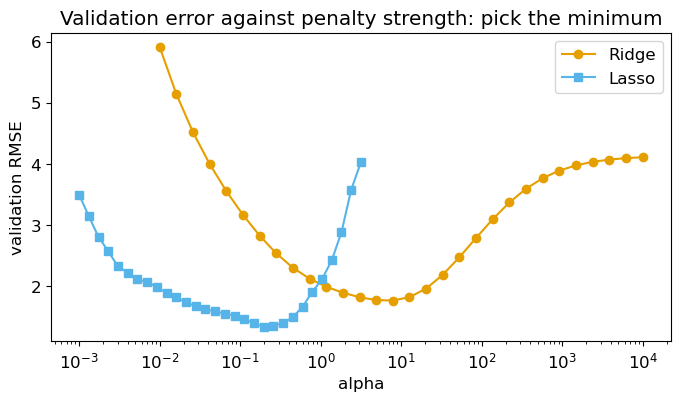

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train_std, y_train, test_size=0.3, random_state=seed)
print(X_fit.shape, X_val.shape)          # 49 points to fit on, 21 to choose alpha with

val_rmse_ridge, val_rmse_lasso = [], []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_fit, y_fit)
    val_rmse_ridge.append(rmse(y_val, ridge.predict(X_val)))
for alpha in alphas_lasso:
    lasso = Lasso(alpha=alpha, max_iter=20000).fit(X_fit, y_fit)
    val_rmse_lasso.append(rmse(y_val, lasso.predict(X_val)))

best_alpha_ridge = alphas[int(np.argmin(val_rmse_ridge))]
best_alpha_lasso = alphas_lasso[int(np.argmin(val_rmse_lasso))]
print(f"ridge: best alpha on validation = {best_alpha_ridge:.3g}")
print(f"lasso: best alpha on validation = {best_alpha_lasso:.3g}")

fig, ax = plt.subplots()
ax.plot(alphas, val_rmse_ridge, "o-", label="Ridge")
ax.plot(alphas_lasso, val_rmse_lasso, "s-", label="Lasso")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("validation RMSE")
ax.set_title("Validation error against penalty strength: pick the minimum")
ax.legend()
plt.show()


Both validation curves are U-shaped against log alpha: Ridge bottoms out near alpha ≈ 8, Lasso near 0.2. Left of the minimum the model overfits the 49 fitting points; right of it everything shrinks toward the mean.

> **Check your understanding.** Why is alpha chosen on the validation set rather than on the test set, when the test set here is larger (30 points against 21)?


In [8]:
ridge_best = Ridge(alpha=best_alpha_ridge).fit(X_train_std, y_train)
lasso_best = Lasso(alpha=best_alpha_lasso, max_iter=20000).fit(X_train_std, y_train)

print(f"OLS    test RMSE {rmse(y_test, ols.predict(X_test_std)):.3f}")
print(f"Ridge  test RMSE {rmse(y_test, ridge_best.predict(X_test_std)):.3f}")
print(f"Lasso  test RMSE {rmse(y_test, lasso_best.predict(X_test_std)):.3f}   "
      f"({int((lasso_best.coef_ != 0).sum())} of {n_features} features kept: {np.flatnonzero(lasso_best.coef_).tolist()})")
print(f"(noise level in the data: {noise_level})")


OLS    test RMSE 1.946
Ridge  test RMSE 2.076
Lasso  test RMSE 1.253   (10 of 50 features kept: [0, 1, 2, 3, 4, 11, 14, 24, 37, 46])
(noise level in the data: 1.0)


Lasso beats OLS by a wide margin and keeps a short list that contains the five features that generated the data, plus a few false positives. Ridge barely moves: on this particular draw of the data the best Ridge can do at *any* alpha is a test RMSE of 1.92 against OLS's 1.95, and the validation-chosen alpha overshoots even that. Do not over-read it. Change the seed and re-run (Exercise 3): on most draws of these same synthetic data Ridge cuts the OLS error by around 10 % and Lasso by about a third. What is robust is the gap between them, and the reason is that the truth is **sparse**: 45 of the 50 coefficients should be exactly zero, which Lasso can express and Ridge cannot. Ridge is the right medicine when many features each matter a little, which is common in physical problems with correlated inputs; Lasso is the right medicine when few matter.

The validation sweep fitted each model on only 49 points and judged it on 21, and that shapes the curve we chose from. Because these data are synthetic we can do something that is never possible with real data: compute the error on the *test* set for every alpha and compare it with the validation curve we actually used.


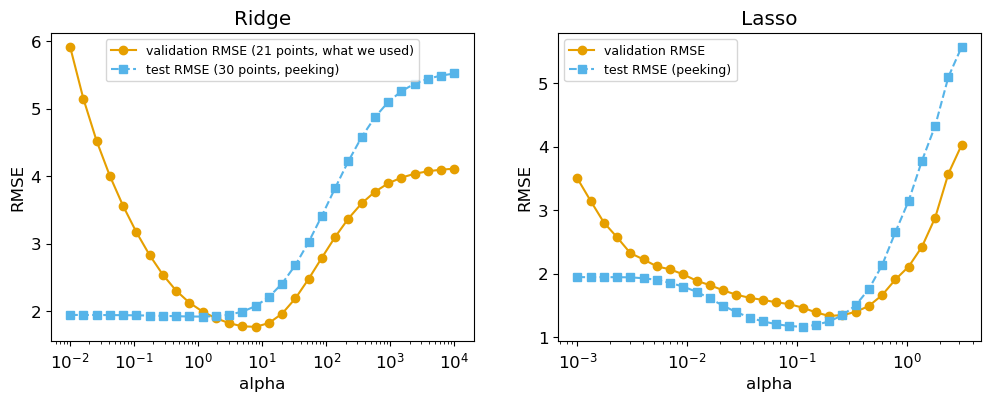

In [9]:
test_rmse_ridge, test_rmse_lasso = [], []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train_std, y_train)
    test_rmse_ridge.append(rmse(y_test, ridge.predict(X_test_std)))
for alpha in alphas_lasso:
    lasso = Lasso(alpha=alpha, max_iter=20000).fit(X_train_std, y_train)
    test_rmse_lasso.append(rmse(y_test, lasso.predict(X_test_std)))

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4))
ax_left.plot(alphas, val_rmse_ridge, "o-", label="validation RMSE (21 points, what we used)")
ax_left.plot(alphas, test_rmse_ridge, "s--", label="test RMSE (30 points, peeking)")
ax_left.set_xscale("log")
ax_left.set_xlabel("alpha")
ax_left.set_ylabel("RMSE")
ax_left.set_title("Ridge")
ax_left.legend(fontsize=9)
ax_right.plot(alphas_lasso, val_rmse_lasso, "o-", label="validation RMSE")
ax_right.plot(alphas_lasso, test_rmse_lasso, "s--", label="test RMSE (peeking)")
ax_right.set_xscale("log")
ax_right.set_xlabel("alpha")
ax_right.set_ylabel("RMSE")
ax_right.set_title("Lasso")
ax_right.legend(fontsize=9)
plt.show()


Dashed lines are the curves we would like to minimize; solid lines are the estimates we used. For Ridge the test curve is nearly flat from tiny alpha up to about 10 and then rises, while the validation curve looks completely different at small alpha; for Lasso the two curves agree on roughly where the minimum lies.

The Ridge validation curve misbehaves at small alpha because the sweep fitted on only 49 points, fewer than the 50 features: an unpenalized model then interpolates the fitting points exactly and fails on the rest. Its minimum lands where the test curve happens to begin rising, so the chosen alpha was partly luck. The lesson: a validation curve is an estimate whose shape depends on how much data was left to fit on. Week 3's cross-validation re-uses the training data several times over to make this estimate far more reliable; until then, treat a validation curve as an estimate with error bars you cannot see.

> **Exercise.** Predict what the Ridge validation curve looks like if the features are *not* standardized. These synthetic features all happen to have similar spreads (standard deviations between 0.9 and 1.4), so first make the scales differ, as they do in real tables: `X_raw = X_train.copy()` and then `X_raw[:, :5] *= [1000, 0.001, 100, 0.01, 1]` puts the five informative features on wildly different scales. Split `X_raw` exactly as `X_train_std` was split (same `test_size` and `random_state`), repeat the Ridge alpha sweep, and compare the best alpha and the test RMSE with the standardized result (rescale `X_test` the same way before testing).


In [10]:
# Exercise 2: work here
np.random.seed(seed)


> **Exercise.** Change `seed` at the top of the notebook to 0, then 1, then 2, and *Restart kernel and run all* each time. Write down the three test RMSEs (OLS, Ridge, Lasso) for each seed. Does Ridge still fail to beat OLS? Does Lasso still win? Put the seed back to 42 afterwards.


## Summary

- Regularization keeps a flexible model but penalizes large coefficients; the penalty strength alpha is a flexibility dial.
- Ridge (squared penalty) shrinks every coefficient smoothly but never to zero and suits problems where many features each matter a little; Lasso (absolute penalty) sets coefficients exactly to zero, selects features, and suits problems where few matter.
- Standardize features first, choose alpha on a validation set, and report the test error once. A small validation set chooses alpha noisily; Week 3's cross-validation is the remedy.


## Exercise solutions

### Exercise 1 (alpha = 10)

All fifty coefficients are exactly zero; the model predicts the training mean of `y` (the intercept, −0.26) for every sample. Maximal penalty means maximal bias: the model has become the baseline.

### Exercise 2 (no standardization)

On the rescaled features the penalty falls hardest on the features that now have small numerical ranges (their coefficients must be large to have any effect) and barely touches the ones with large ranges, regardless of how useful they are. The validation curve shifts to the right (best alpha ≈ 53 instead of 7.9) and the test RMSE is worse, 2.40 against 2.08; no alpha does better than 2.39 on the rescaled features. Standardize before regularizing, every time. (Had you skipped the rescaling step, almost nothing would have changed, because these synthetic columns already share a scale; real tables, with areas in km² next to fractions between 0 and 1, never do.)

### Exercise 3 (other seeds)

Seed 0: OLS 1.70, Ridge 1.57, Lasso 1.12. Seed 1: OLS 1.73, Ridge 2.42, Lasso 1.17. Seed 2: OLS 1.98, Ridge 1.73, Lasso 0.83. Lasso wins every time by a wide margin; Ridge usually beats OLS by a little (two of these three seeds, and about 30 of 40 seeds overall), but the validation-chosen alpha is sometimes badly off, as seed 1 shows. The ordering OLS > Ridge > Lasso is the robust result for a sparse truth; the exact numbers are not.

### Check-your-understanding answers

- *Near-perfect copies.* Ridge tends to keep both with similar, roughly halved coefficients (the squared penalty prefers two medium coefficients to one large one); Lasso tends to keep one and drop the other, and which one survives can change with a different training set.
- *Validation, not test.* The test set is reserved for a single honest report at the end. Choosing alpha on it would tune the model to those 30 points, and the test RMSE would then flatter the model, exactly as the training error flatters a flexible model. Its size does not change its job.
